# Field Samples Exploration - reference example

> **Hand-written reference** for notebook `3_explore-and-plan`. Compare it with the notebook your assistant generated:
> it is not the only correct solution, but it shows what a careful first exploration of *this* raw file should reveal.

## Introduction
We explore the raw file `../data/field_samples_raw.csv` before any cleaning. The goal is to understand its structure and quality,
and to collect facts for the Data Management Plan (DMP). We do **not** change the data here.

## Planned steps
1. Load the data - without assumptions about column names
2. Structure: shape, columns, inferred types
3. Missing values - including *hidden* missing-value codes
4. Categorical columns - spelling variants of the same category
5. Numeric columns stored as text
6. Outliers and impossible values
7. Distributions
8. Summary for the DMP

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

### Step 1: Load the data
We read the file as it is, so that we see exactly what a data provider handed over.

In [2]:
file_path = Path("../data/field_samples_raw.csv")
df = pd.read_csv(file_path)
df.head()

,sample_id,species,island,date_collected,body_mass_g,flipper_length_mm,sex,region,notes
0,S0001,Adelie,Torgersen,2021-12-04,4547,201.2,.,Antarctica,juvenile?
1,S0002,Gentoo,NaN,2023-05-26,4650,212.4,Male,Antarctica,NaN
2,S0003,adelie,NaN,2022-10-09,2104,191.5,NaN,Antarctica,NaN
3,S0004,Chinstrap,Bisco,22/01/2021,5766,197.4,F,Antarctica,NaN
4,S0005,Chinstrap,Dream,2021-11-09,4814,219.9,F,Antarctica,NaN


### Step 2: Structure
How many records and variables, and which types did `pandas` infer? Columns that *should* be numbers but are `object` (text) are a first warning sign.

In [3]:
print("Shape (rows, columns):", df.shape)
df.dtypes

Shape (rows, columns): (182, 9)


sample_id            object
species              object
island               object
date_collected       object
body_mass_g          object
flipper_length_mm    object
sex                  object
region               object
notes                object
dtype: object

### Step 3: Missing values
`pandas` only recognises empty cells and a few standard codes as missing. Data providers often use their own codes, so we also count typical placeholder values.

In [4]:
PLACEHOLDERS = ["-999", "NULL", "?", "n/a", "NA", ""]

missing = pd.DataFrame({
    "recognised_missing": df.isna().sum(),
    "placeholder_codes": df.astype(str).apply(lambda s: s.str.strip().isin(PLACEHOLDERS).sum()),
})
missing["share_%"] = (100 * missing.sum(axis=1) / len(df)).round(1)
missing

,recognised_missing,placeholder_codes,share_%
sample_id,0,0,0.0
species,0,0,0.0
island,43,0,23.6
date_collected,9,0,4.9
body_mass_g,8,7,8.2
flipper_length_mm,8,3,6.0
sex,21,0,11.5
region,0,0,0.0
notes,161,0,88.5


### Step 4: Categorical columns
For columns with few distinct values we list all spellings. Variants of the same category (casing, whitespace, typos) point to a missing controlled vocabulary.

In [5]:
categorical_cols = [c for c in df.columns if df[c].dtype == object and df[c].nunique() <= 15]
for col in categorical_cols:
    print(f"{col}:")
    print(df[col].value_counts(dropna=False).to_string(), "\n")

species:
species
Chinstrap Penguin    22
Gentooo              20
Gentoo               19
Adelie               18
adelie               17
chinstrap            17
Chinstrap            16
ADELIE               16
gentoo               14
Adelie               13
 Adelie              10 

island:
island
NaN          43
Bisco        41
Torgersen    40
Dream        34
Biscoe       24 

sex:
sex
.          23
NaN        21
Male       19
Female     18
unknown    18
F          17
M          15
FEMALE     15
female     13
male       12
MALE       11 

region:
region
Antarctica    182 

notes:
notes
NaN                               161
weather: storm                      8
re-measured                         6
juvenile?                           3
tag damaged                         3
collected near Pointe Géologie      1 



### Step 5: Numeric columns stored as text
We try to convert every column to a number and look at the values that fail. These show *why* a column was read as text.

In [6]:
as_num = df.apply(pd.to_numeric, errors="coerce")
numeric_cols = [c for c in df.columns if as_num[c].notna().mean() > 0.8]

for col in numeric_cols:
    not_numeric = df.loc[as_num[col].isna() & df[col].notna(), col]
    print(f"{col}: {len(not_numeric)} values are not plain numbers, e.g. {not_numeric.unique()[:6].tolist()}")

body_mass_g: 15 values are not plain numbers, e.g. ['4168 g', '4847 g', '4720 g', '3645 g', '3854 g', '4540 g']
flipper_length_mm: 12 values are not plain numbers, e.g. ['207,9', '219,2', '208,0', '217,3', '211,9', '219,3']


### Step 6: Outliers and impossible values
For the values that *are* numeric we use the interquartile range (IQR). We also check for physically impossible values (negative masses or lengths).

In [7]:
for col in numeric_cols:
    s = as_num[col].replace(-999, float("nan")).dropna()  # -999 is a missing code, not a value
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    outliers = s[(s < lo) | (s > hi)]
    print(f"{col}: {len(outliers)} IQR outliers outside [{lo:.1f}, {hi:.1f}], "
          f"{(s < 0).sum()} negative values; extreme values: {sorted(float(v) for v in outliers.unique())[:8]}")

body_mass_g: 9 IQR outliers outside [1973.0, 6267.0], 4 negative values; extreme values: [-200.0, 6382.0, 99999.0]
flipper_length_mm: 6 IQR outliers outside [153.8, 251.0], 0 negative values; extreme values: [1888.0, 2028.0, 2106.0, 2167.0, 2178.0]


### Step 7: Distributions
We plot the plausible range only, so that single extreme values do not hide the shape of the distribution.

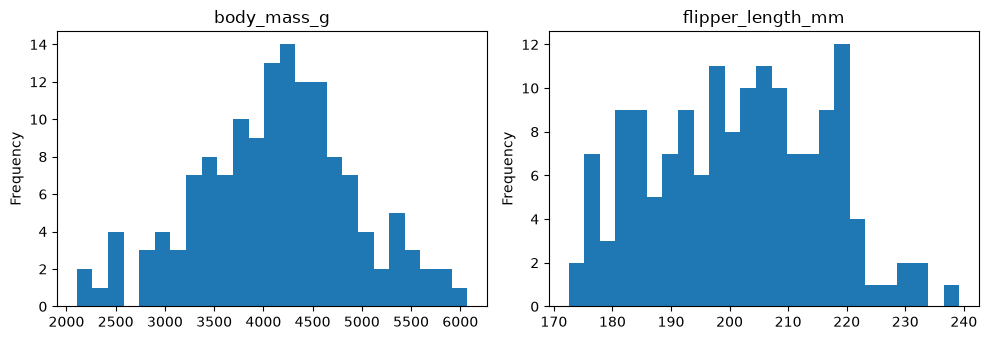

In [8]:
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(5 * len(numeric_cols), 3.5))
for ax, col in zip(axes, numeric_cols):
    s = as_num[col].replace(-999, float("nan")).dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    s[(s >= q1 - 1.5 * (q3 - q1)) & (s <= q3 + 1.5 * (q3 - q1))].plot.hist(bins=25, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Step 7b: Date formats
How many dates follow ISO 8601 (`YYYY-MM-DD`), and what do the others look like?

In [9]:
dates = df["date_collected"].dropna()
is_iso = dates.str.match(r"^\d{4}-\d{2}-\d{2}$")
print(f"ISO dates: {is_iso.sum()} of {len(dates)}; examples of other formats: {dates[~is_iso].unique()[:6].tolist()}")

ISO dates: 41 of 173; examples of other formats: ['22/01/2021', '5.8.2023', '4.9.2021', '4.1.2022', '6.9.2022', '04/08/2023']


### Step 8: Summary for the DMP
The summary is computed from the results above, so every number in it can be traced back to a cell in this notebook.

In [10]:
summary = f"""
Dataset: {file_path.name}, {len(df)} records, {df.shape[1]} variables, CSV.
Duplicates: {df.duplicated().sum()} exact duplicate rows.
Missing values: recognised by pandas in {int((missing['recognised_missing'] > 0).sum())} columns;
  additional placeholder codes ({', '.join(p for p in PLACEHOLDERS if p)}) found in
  {int((missing['placeholder_codes'] > 0).sum())} columns.
Categorical columns with casing/whitespace variants: {[c for c in categorical_cols if df[c].str.strip().str.lower().nunique() < df[c].nunique()]}
  (typos and long forms, e.g. in island or species, need a manual look - see step 4).
Numeric columns stored as text: {numeric_cols} (units, comma decimals).
Dates: {is_iso.sum()} of {len(dates)} in ISO 8601, the rest in other formats.
Next steps: define a schema (data contract), clean formatting issues, flag impossible values
  back to the data provider, document everything in a data package.
"""
print(summary)


Dataset: field_samples_raw.csv, 182 records, 9 variables, CSV.
Duplicates: 2 exact duplicate rows.
Missing values: recognised by pandas in 6 columns;
  additional placeholder codes (-999, NULL, ?, n/a, NA) found in
  2 columns.
Categorical columns with casing/whitespace variants: ['species', 'sex']
  (typos and long forms, e.g. in island or species, need a manual look - see step 4).
Numeric columns stored as text: ['body_mass_g', 'flipper_length_mm'] (units, comma decimals).
Dates: 41 of 173 in ISO 8601, the rest in other formats.
Next steps: define a schema (data contract), clean formatting issues, flag impossible values
  back to the data provider, document everything in a data package.

